# Vision — Anotasi Sendiri untuk Deteksi Objek (auto-label YOLO)
**Kapan dipakai:** gambar **belum punya kotak** dan harus dilabeli sendiri.

**Langkah:** YOLO pretrained menebak kotak (auto-label) → lihat grid hasilnya → perbaiki yang
salah → susun folder YOLO → fine-tune → cek mAP. Tanpa GUI, tanpa internet.

**Data demo:** PennFudanPed (170 foto pejalan kaki). Kotak aslinya **tidak dipakai** sampai sel
kunci jawaban terakhir, hanya untuk mengukur mutu label kita.

In [1]:
import glob
import os
import re
import shutil

import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/detection/PennFudanPed"   # GANTI
IMAGE_FOLDER = f"{DATA_FOLDER}/PNGImages"
KEY_FOLDER = f"{DATA_FOLDER}/Annotation"     # kotak asli, hanya ada di data latihan
IMAGE_EXTENSION = ".png"                      # ganti ".jpg" bila perlu
YOLO_WEIGHTS = "../../pretrained/yolov8n/yolov8n.pt"
LABEL_FOLDER = "labels_auto"     # file .txt hasil auto-label (di folder notebook)
DATASET_FOLDER = "dataset"       # folder YOLO images/ + labels/ (di folder notebook)

IMAGE_SIZE = 640
EPOCHS = 5
BATCH_SIZE = 8
VAL_FRACTION = 0.2    # bagian gambar yang jadi data val
N_GRID = 8            # jumlah gambar per grid tinjauan (genap)
MIN_CONFIDENCE = 0.25   # kotak dengan keyakinan di bawah ini dibuang
MIN_AREA = 0.01       # kotak lebih kecil dari 1% gambar dibuang
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0

CLASS_MAP = {0: 0}               # id kelas COCO -> id kelas kita (COCO 0 = person)
CLASS_NAMES = {0: "pejalan"}     # id kelas kita -> nama
# CLASS_MAP = {2: 0, 5: 1, 7: 1}    # contoh kelas sendiri: car -> 0; bus dan truck -> 1
# CLASS_NAMES = {0: "mobil", 1: "kendaraan_besar"}

# Koreksi manual: isi SETELAH melihat grid, lalu jalankan ulang dari sel koreksi
DELETE_ROWS = {}      # contoh: {"FudanPed00007": [1]} -> hapus baris ke-1 (mulai dari 0)
CHANGE_CLASS = {}     # contoh: {"FudanPed00003": {0: 1}} -> baris ke-0 jadi kelas 1
ADD_BOXES = {}        # contoh: {"FudanPed00010": [(0, 100, 50, 220, 400)]}
#                       = (kelas, kiri, atas, kanan, bawah) dalam piksel

## Baca data (gambar tanpa label)

In [3]:
image_paths = sorted(glob.glob(f"{IMAGE_FOLDER}/*{IMAGE_EXTENSION}"))
image_names = []
for image_path in image_paths:
    image_names.append(os.path.splitext(os.path.basename(image_path))[0])
print("jumlah gambar:", len(image_paths), "| ukuran contoh:", Image.open(image_paths[0]).size)

jumlah gambar: 170 | ukuran contoh: (559, 536)


## Auto-label: YOLO pretrained menebak kotak, ditulis sebagai file `.txt` format YOLO
Satu baris = `kelas cx cy w h` (titik tengah, lebar, tinggi; semua 0–1 relatif ukuran gambar).

In [4]:
os.makedirs(LABEL_FOLDER, exist_ok=True)
model = YOLO(YOLO_WEIGHTS)
results = model.predict(image_paths, conf=MIN_CONFIDENCE, imgsz=IMAGE_SIZE, device=DEVICE,
                        verbose=False)

box_counts = []
lowest_confidence = []
for name, result in zip(image_names, results):
    lines = []
    scores = []
    for box_number in range(len(result.boxes)):
        coco_class = int(result.boxes.cls[box_number])
        cx, cy, width, height = result.boxes.xywhn[box_number].tolist()
        if coco_class in CLASS_MAP and width * height >= MIN_AREA:
            lines.append(f"{CLASS_MAP[coco_class]} {cx:.6f} {cy:.6f} {width:.6f} {height:.6f}")
            scores.append(float(result.boxes.conf[box_number]))
    with open(f"{LABEL_FOLDER}/{name}.txt", "w") as file:
        file.write("\n".join(lines))
    box_counts.append(len(lines))
    lowest_confidence.append(min(scores, default=0))

summary = pd.DataFrame()
summary["image"] = image_names
summary["n_boxes"] = box_counts
summary["min_conf"] = lowest_confidence
print("total kotak:", summary["n_boxes"].sum())
print("gambar tanpa deteksi:", (summary["n_boxes"] == 0).sum())

WARNING NMS time limit 2.050s exceeded


total kotak: 595
gambar tanpa deteksi: 0


## Tinjau: gambar + kotak dari file label (sumber kebenaran = file `.txt`)
Dua grid: 8 gambar acak, dan 8 gambar yang keyakinannya paling rendah (cek ini lebih dulu).

             image  n_boxes  min_conf
42   FudanPed00043        8  0.255467
24   FudanPed00025        8  0.258776
79    PennPed00006        6  0.262386
74    PennPed00001       11  0.262913
45   FudanPed00046       10  0.263770
75    PennPed00002       11  0.267498
82    PennPed00009       15  0.267633
101   PennPed00028        2  0.267670


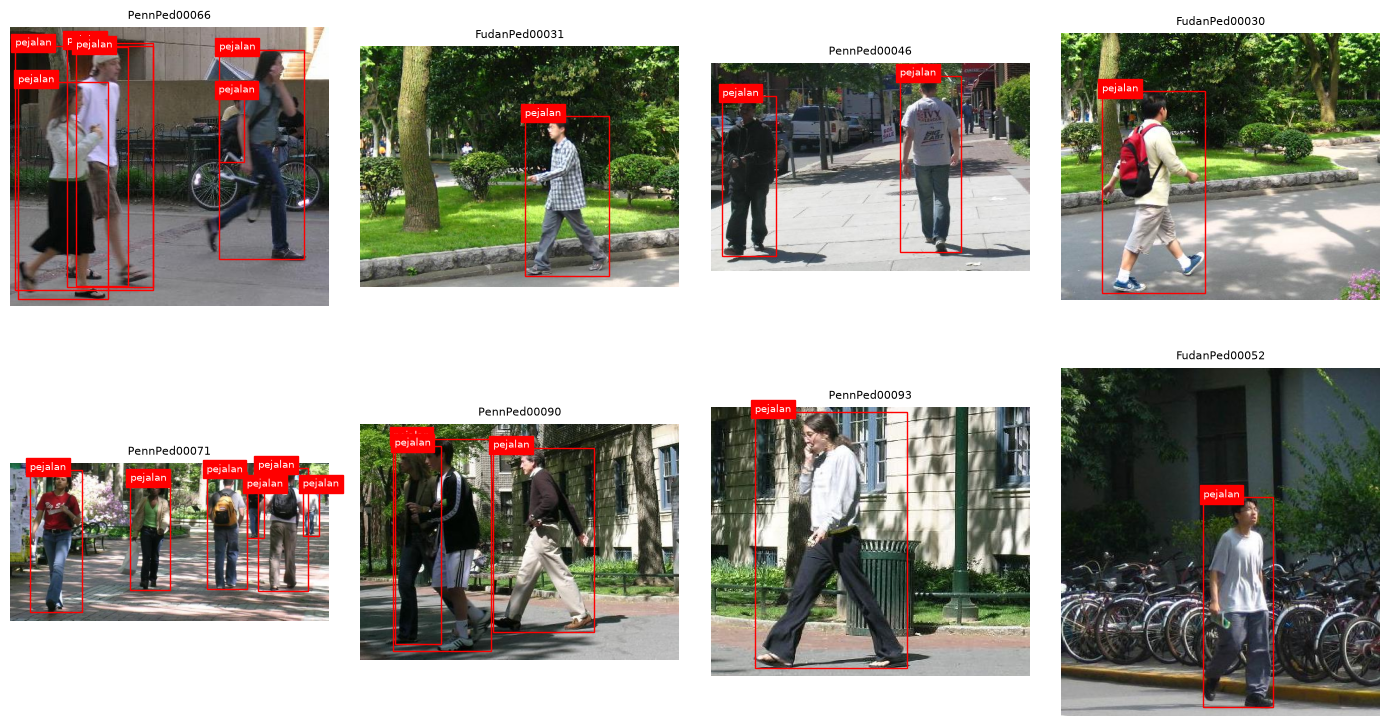

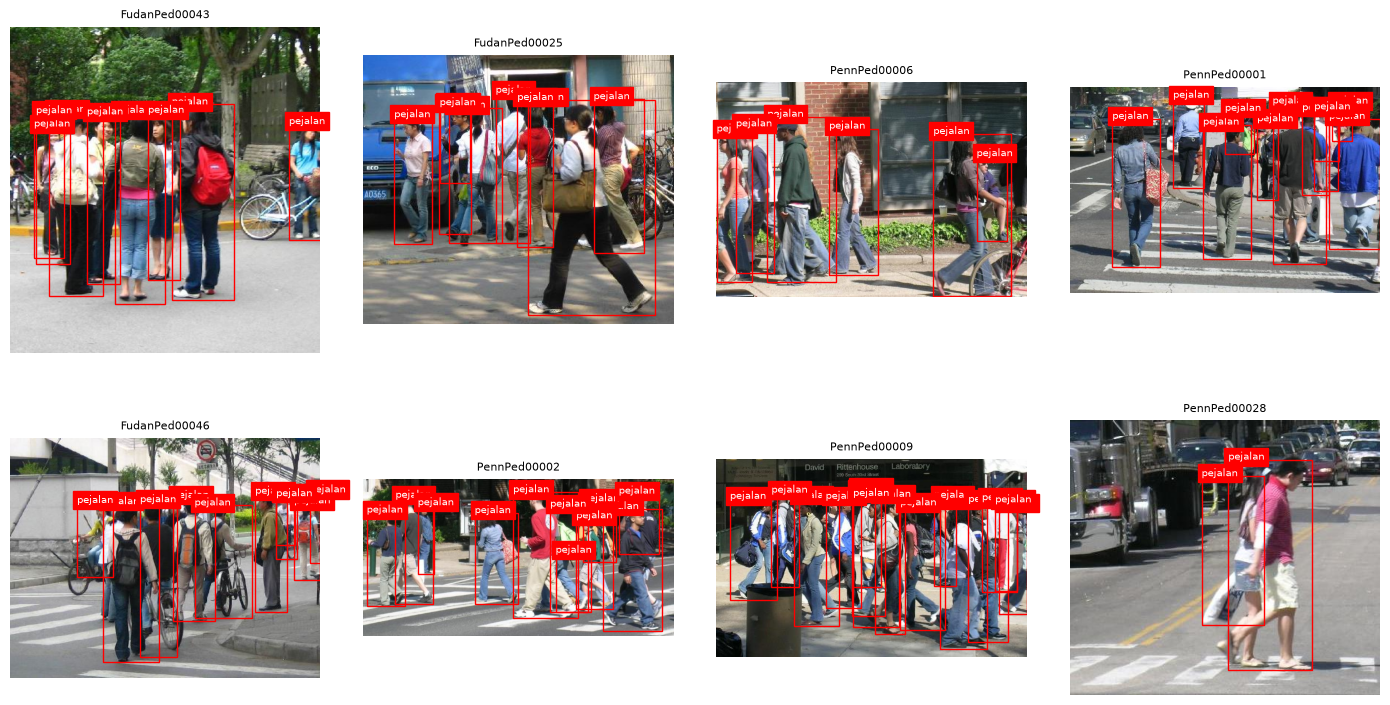

In [5]:
def show_boxes(names, file_name):
    fig, axes = plt.subplots(2, N_GRID // 2, figsize=(14, 8))
    for ax, name in zip(axes.ravel(), names):
        image = Image.open(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}")
        ax.imshow(image)
        for line in open(f"{LABEL_FOLDER}/{name}.txt").read().splitlines():
            class_id, cx, cy, width, height = line.split()
            box_width = float(width) * image.width
            box_height = float(height) * image.height
            left = float(cx) * image.width - box_width / 2
            top = float(cy) * image.height - box_height / 2
            ax.add_patch(Rectangle((left, top), box_width, box_height, fill=False, color="red"))
            ax.text(left, top, CLASS_NAMES[int(class_id)], color="white", backgroundcolor="red",
                    fontsize=7)
        ax.set_title(name, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(file_name, dpi=80)
    plt.show()


check_first = summary.sort_values("min_conf").head(N_GRID)
print(check_first)
show_boxes(summary.sample(N_GRID, random_state=SEED)["image"], "grid_acak.png")
show_boxes(check_first["image"], "grid_perlu_dicek.png")

## Koreksi: hapus baris, ubah kelas
Cara tercepat tetap membuka file `labels_auto/<nama>.txt` dan mengedit barisnya langsung.

In [6]:
for name in DELETE_ROWS:
    label_file = f"{LABEL_FOLDER}/{name}.txt"
    lines = open(label_file).read().splitlines()
    kept = []
    for line_number in range(len(lines)):
        if line_number not in DELETE_ROWS[name]:
            kept.append(lines[line_number])
    with open(label_file, "w") as file:
        file.write("\n".join(kept))

for name in CHANGE_CLASS:
    label_file = f"{LABEL_FOLDER}/{name}.txt"
    lines = open(label_file).read().splitlines()
    for line_number in CHANGE_CLASS[name]:
        box_numbers = lines[line_number].split(" ", 1)[1]     # "cx cy w h" tanpa kelas
        lines[line_number] = f"{CHANGE_CLASS[name][line_number]} {box_numbers}"
    with open(label_file, "w") as file:
        file.write("\n".join(lines))

## Koreksi: tambah kotak manual (koordinat piksel → format YOLO)

In [7]:
for name in ADD_BOXES:
    image = Image.open(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}")
    new_lines = ""
    for class_id, left, top, right, bottom in ADD_BOXES[name]:
        cx = (left + right) / 2 / image.width
        cy = (top + bottom) / 2 / image.height
        width = (right - left) / image.width
        height = (bottom - top) / image.height
        new_lines = new_lines + f"\n{class_id} {cx:.6f} {cy:.6f} {width:.6f} {height:.6f}"
    with open(f"{LABEL_FOLDER}/{name}.txt", "a") as file:
        file.write(new_lines)

## Susun folder YOLO: `images/train`, `images/val`, `labels/train`, `labels/val`, `data.yaml`

In [8]:
shutil.rmtree(DATASET_FOLDER, ignore_errors=True)     # mulai dari folder kosong
train_names, val_names = train_test_split(image_names, test_size=VAL_FRACTION,
                                          random_state=SEED)
for part, names in [("train", train_names), ("val", val_names)]:
    os.makedirs(f"{DATASET_FOLDER}/images/{part}")
    os.makedirs(f"{DATASET_FOLDER}/labels/{part}")
    for name in names:
        shutil.copy(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}", f"{DATASET_FOLDER}/images/{part}")
        shutil.copy(f"{LABEL_FOLDER}/{name}.txt", f"{DATASET_FOLDER}/labels/{part}")

dataset_path = os.path.abspath(DATASET_FOLDER).replace("\\", "/")   # YOLO butuh path lengkap
yaml_text = f"path: {dataset_path}\ntrain: images/train\nval: images/val\nnames:\n"
for class_id in CLASS_NAMES:
    yaml_text = yaml_text + f"  {class_id}: {CLASS_NAMES[class_id]}\n"
with open(f"{DATASET_FOLDER}/data.yaml", "w") as file:
    file.write(yaml_text)
print(yaml_text)
print("train:", len(train_names), "| val:", len(val_names))

path: ../../_.NEW-GEN/vision/dataset
train: images/train
val: images/val
names:
  0: pejalan

train: 136 | val: 34


## Fine-tune singkat dari bobot pretrained, lalu mAP di data val
mAP di sini diukur terhadap label hasil anotasi kita sendiri.

In [9]:
model = YOLO(YOLO_WEIGHTS)
model.train(data=f"{DATASET_FOLDER}/data.yaml", epochs=EPOCHS, imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE, workers=0, device=DEVICE, project="runs", name="train",
            exist_ok=True, plots=False, seed=SEED)

model = YOLO(model.trainer.best)        # file bobot terbaik hasil latih
metrics = model.val(data=f"{DATASET_FOLDER}/data.yaml", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
                    workers=0, device=DEVICE, project="runs", name="val", exist_ok=True,
                    plots=False, verbose=False)
print("mAP50:", round(metrics.box.map50, 4), "| mAP50-95:", round(metrics.box.map, 4))

New https://pypi.org/project/ultralytics/8.4.182 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.172  Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../../pretrained/yolov8n/yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=False, p

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 4/5 5.0it/s 0.6s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.3it/s 0.7s

                   all         34        139      0.944      0.583       0.76      0.578


Speed: 0.3ms preprocess, 7.6ms inference, 0.0ms loss, 1.4ms postprocess per image


mAP50: 0.76 | mAP50-95: 0.5779


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Kotak asli PennFudan (`Annotation/*.txt`, berisi "(kiri, atas) - (kanan, bawah)") diubah ke
format YOLO untuk gambar val. Hasilnya: seberapa bagus model dari label kita bila diukur dengan
label manusia.

In [10]:
KEY_DATASET = "dataset_kunci"
shutil.rmtree(KEY_DATASET, ignore_errors=True)
os.makedirs(f"{KEY_DATASET}/images/val")
os.makedirs(f"{KEY_DATASET}/labels/val")
for name in val_names:
    image_file = f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}"
    shutil.copy(image_file, f"{KEY_DATASET}/images/val")
    image = Image.open(image_file)
    key_text = open(f"{KEY_FOLDER}/{name}.txt").read()
    lines = []
    for left, top, right, bottom in re.findall(r"\((\d+), (\d+)\) - \((\d+), (\d+)\)", key_text):
        cx = (int(left) + int(right)) / 2 / image.width
        cy = (int(top) + int(bottom)) / 2 / image.height
        width = (int(right) - int(left)) / image.width
        height = (int(bottom) - int(top)) / image.height
        lines.append(f"0 {cx:.6f} {cy:.6f} {width:.6f} {height:.6f}")
    with open(f"{KEY_DATASET}/labels/val/{name}.txt", "w") as file:
        file.write("\n".join(lines))

key_path = os.path.abspath(KEY_DATASET).replace("\\", "/")
with open(f"{KEY_DATASET}/data.yaml", "w") as file:
    file.write(f"path: {key_path}\ntrain: images/val\nval: images/val\nnames:\n  0: pejalan\n")
metrics = model.val(data=f"{KEY_DATASET}/data.yaml", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
                    workers=0, device=DEVICE, project="runs", name="val_kunci", exist_ok=True,
                    plots=False, verbose=False)
print("mAP50 terhadap label manusia:", round(metrics.box.map50, 4))

Ultralytics 8.4.172  Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 1659.91079.2 MB/s, size: 309.2 KB)


val: Scanning Z:\GEMASTIK-DATABASE\_.NEW-GEN\vision\dataset_kunci\labels\val... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 431.9it/s 0.1s

val: New cache created: Z:\GEMASTIK-DATABASE\_.NEW-GEN\vision\dataset_kunci\labels\val.cache


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 4/5 6.1it/s 0.5s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 9.3it/s 0.5s

                   all         34         88      0.914      0.846      0.913      0.692


Speed: 0.3ms preprocess, 2.8ms inference, 0.0ms loss, 1.5ms postprocess per image


mAP50 terhadap label manusia: 0.9126
